In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [15]:
df_all = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/all0818_2_all.csv')

In [16]:
df_all.shape[0]

2528083

In [11]:
df_allreco = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/all0818_2_allreco.csv')

In [12]:
df_allreco.shape[0]

2528083

Do a trivial closure test to get 100% closure

In [74]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [75]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

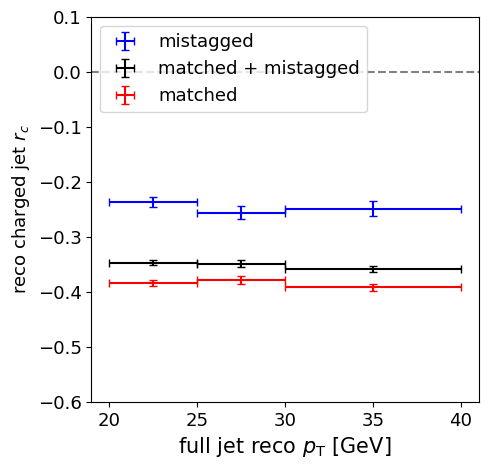

In [76]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [77]:
rc_allreco_bs_vs_pts_array

[-0.34624982290560824,
 -0.3469139583410006,
 -0.34909028269835457,
 -0.3586959637988906]

In [78]:
rc_err_allreco_bs_vs_pts_array

[0.003989944604545351,
 0.004733961363515017,
 0.00600734362065285,
 0.005686699309277501]

In [79]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [80]:
b_fake_array = []
b_err_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))
    b_err_fake_array.append(yerr_fake_rec/sum(y_fake_rec))

In [81]:
b_fake_array

[array([0.62543183, 0.37456817]),
 array([0.61873109, 0.38126891]),
 array([0.62803764, 0.37196236]),
 array([0.62463995, 0.37536005]),
 array([0.63944094, 0.36055906])]

In [82]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [83]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

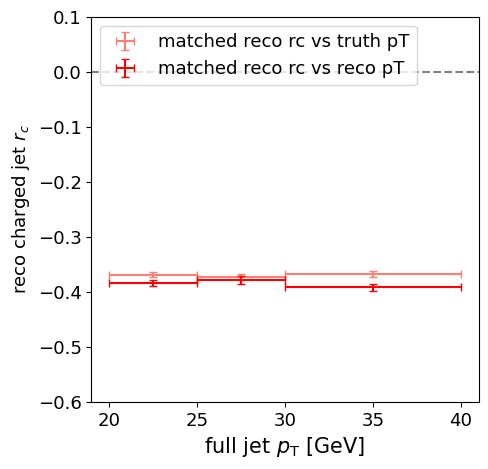

In [84]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [85]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))

In [86]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_2135051/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [87]:
eff4

array([       nan,        nan, 0.69831139, 0.74593234, 0.75645532,
       0.76711444, 0.76569572])

In [88]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.30168861, 0.25406766, 0.24354468, 0.23288556, 0.23430428])

In [89]:
b_allreco_array = []
b_err_allreco_array = []
for i in range(0,4):
    df_allreco_pts = df_allreco_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_allreco_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_pts['ws'], density=True)
    b_allreco_array.append(y_reco/sum(y_reco))
    b_err_allreco_array.append(yerr_reco/sum(y_reco))

In [90]:
def subtractFake(data, fake_rate, fake_dist):
    corrected = (data - fake_rate * fake_dist)/(1 - fake_rate)
    return corrected

In [91]:
b_fakesubtracted_array = []
b_err_fakesubtracted_array = []
rc_fakesubtracted_array = []
rc_err_fakesubtracted_array = []
for i in range(0,4):
    print(i)
    #print(b_allreco_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted = subtractFake(b_allreco_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_err_fakesubtracted = np.sqrt(b_err_allreco_array[i]**2+(fake_rate_array[i]*b_err_fake_array[i])**2)
    b_err_fakesubtracted_array.append(b_err_fakesubtracted)
    print(b_fakesubtracted)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    rc_fakesubtracted = (nss-nos) / (nss+nos)
    rc_fakesubtracted_array.append(rc_fakesubtracted)
    rc_err_fakesubtracted = 2*b_err_fakesubtracted[0]
    rc_err_fakesubtracted_array.append(rc_err_fakesubtracted)

0
[0.69372956 0.30627044]
1
[0.69209685 0.30790315]
2
[0.68951847 0.31048153]
3
[0.6959566 0.3040434]


In [92]:
rc_fakesubtracted_array

[-0.38745911297903,
 -0.3841936924007314,
 -0.37903694243875447,
 -0.39191319994020163]

In [93]:
rc_err_fakesubtracted_array

[0.008595360311569808,
 0.009457800388258764,
 0.010903328427636793,
 0.011365386522128193]

In [94]:
reweight_array = []
for i in range(0,4):
    reweight_array.append((b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i])))

In [95]:
reweight_array

[array([1., 1.]), array([1., 1.]), array([1., 1.]), array([1., 1.])]

Reweight sample 1

In [96]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    else:
        r.append(1)
        #print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

/tmp/ipykernel_2135051/3206524515.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [97]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [98]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [99]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])

In [102]:
print(rc_match_bs_vs_pt_array)

[-0.38824795322170325, -0.36869214375949017, -0.3733421870594875, -0.3679789899982898, -0.3680586574461345]


Obtain truth

In [ ]:
# Prior to 03/10/25, this is done with something analogous to
# df_all = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_all.csv')
# df_alltruth = applyCut(df_all, 'pt>5 and b!=-9')
# I think that is incorrect since df_all include only jets that pass the detector-level cuts

In [100]:
df_alltruth = pd.read_csv('/gpfs/gibbs/project/havener/ys668/other_output/rc/all0818_2_alltruth.csv')

In [64]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [65]:
rc_truth_b_vs_pt_array = []
rc_err_truth_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_truth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    rc_err_truth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

Check closure

In [68]:
plt.rcParams.update({'font.size': 13})

Text(20, -0.48, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$, $|\\eta|<0.6$')

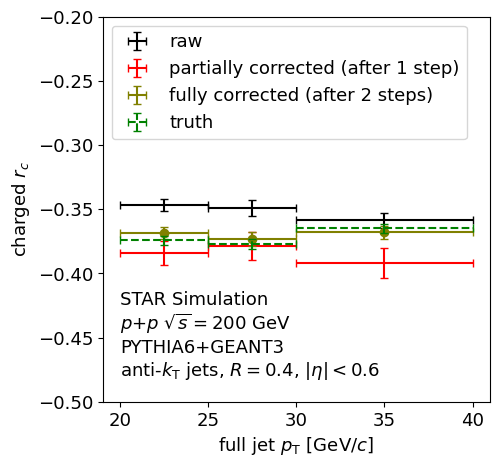

In [69]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='raw')
plt.errorbar([22.5, 27.5, 35], rc_fakesubtracted_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_fakesubtracted_array[1:], capsize=3, color='r', ls='none', label='partially corrected (after 1 step)')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='olive', ls='none', label='fully corrected (after 2 steps)')
plt.plot([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], color='olive', ls='none', marker='o')
eb1 = plt.errorbar([22.5, 27.5, 35], rc_truth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_truth_b_vs_pt_array[1:], capsize=3, color='g', ls='none', label='truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV/$c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.5,-0.2)
plt.legend(loc='upper left')
plt.text(20, -0.48, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nPYTHIA6+GEANT3\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$, $|\eta|<0.6$')

100% closure

In [101]:
df_match = applyCut(df_alltruth, 'pts>15 and bs!=-9 and nefs<0.9 and distance1<0.02 and distance2<0.02')

In [103]:
df_match_pt_array_readfromalltruth = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

In [110]:
rc_match_bs_vs_pt_array_readfromalltruth = []
rc_err_match_bs_vs_pt_array_readfromalltruth = []
for i in range(0, len(df_match_pt_array_readfromalltruth)):
    rc_match_bs_vs_pt_array_readfromalltruth.append(getRcAndErr(df_match_pt_array_readfromalltruth[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array_readfromalltruth.append(getRcAndErr(df_match_pt_array_readfromalltruth[i], 'bs')[1])

In [111]:
print(rc_match_bs_vs_pt_array_readfromalltruth)

[-0.38824795322170325, -0.36869214375949017, -0.3733421870594875, -0.3679789899982899]


In [113]:
np.array(rc_match_bs_vs_pt_array[:-1]) - np.array(rc_match_bs_vs_pt_array_readfromalltruth)

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 5.55111512e-17])